# 05 — Six-Algorithm Model Selection (Real Dataset 2)

**Question:** Which one **simple/interpretable** and one **more flexible/complex** algorithm are promising enough to investigate further?

We screen six predefined algorithms on the **same original 7 features and 3-class target**, with the same fixed training split and identical Stratified 5-Fold CV. We rank by mean CV **Macro-F1**, while also reporting balanced accuracy, overall accuracy, score variability, training accuracy and fit time. A Dummy most-frequent model provides a baseline. This is a **screening decision**, not a claim that the finalists are globally best for all feature/target combinations.

In [1]:
from pathlib import Path
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
MODELS = ROOT / 'models'
for p in [TABLES, FIGURES, MODELS, DATA/'processed']:
    p.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_preprocessor(X):
    numerical = X.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in X.columns if c not in numerical]
    # Fit is performed inside each CV training fold, never before splitting.
    return ColumnTransformer([
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical),
        ('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), numerical)
    ], remainder='drop')


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

meta=json.loads((DATA/'processed'/'experiment_config.json').read_text())
df=pd.read_csv(DATA/'processed'/'dataset2_cleaned.csv')
split=pd.read_csv(DATA/'processed'/'split_indices.csv')
train_mask=split['split'].eq('train').to_numpy()
X=df.loc[train_mask,meta['seven_features']]
y=df.loc[train_mask,meta['target']].map({int(k):v for k,v in meta['three_class_mapping'].items()})
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring={'macro_f1':'f1_macro','accuracy':'accuracy','balanced_accuracy':'balanced_accuracy'}
model_specs={
 'Logistic Regression': (LogisticRegression(max_iter=2000,random_state=42),'simple'),
 'Decision Tree': (DecisionTreeClassifier(random_state=42),'simple'),
 'Random Forest': (RandomForestClassifier(n_estimators=150,random_state=42,n_jobs=1),'complex'),
 'SVM (RBF)': (SVC(),'complex'),
 'KNN': (KNeighborsClassifier(n_neighbors=5),'complex'),
 'Gradient Boosting': (GradientBoostingClassifier(random_state=42),'complex'),
 'Dummy (most frequent)':(DummyClassifier(strategy='most_frequent'),'baseline')
}


## Cross-validate every candidate without accessing the held-out test set

In [3]:
rows=[]; fold_rows=[]
for name,(estimator,group) in model_specs.items():
    pipeline=Pipeline([('preprocess',make_preprocessor(X)),('model',estimator)])
    stats=cross_validate(pipeline,X,y,cv=cv,scoring=scoring,return_train_score=True,n_jobs=1)
    rows.append({'model':name,'group':group,
        'cv_macro_f1':stats['test_macro_f1'].mean(),
        'cv_macro_f1_sd':stats['test_macro_f1'].std(),
        'cv_accuracy':stats['test_accuracy'].mean(),
        'cv_balanced_accuracy':stats['test_balanced_accuracy'].mean(),
        'cv_train_accuracy':stats['train_accuracy'].mean(),
        'cv_train_macro_f1':stats['train_macro_f1'].mean(),
        'mean_fit_time_seconds':stats['fit_time'].mean(),
        'mean_score_time_seconds':stats['score_time'].mean()})
    for i in range(5):
        fold_rows.append({'model':name,'fold':i+1,'val_macro_f1':stats['test_macro_f1'][i],
            'train_macro_f1':stats['train_macro_f1'][i],
            'val_accuracy':stats['test_accuracy'][i],
            'train_accuracy':stats['train_accuracy'][i],
            'val_balanced_accuracy':stats['test_balanced_accuracy'][i]})
results=pd.DataFrame(rows).sort_values(['group','cv_macro_f1'],ascending=[True,False])
display(results.round(4))
results.to_csv(TABLES/'model_selection_6_models.csv',index=False)
pd.DataFrame(fold_rows).to_csv(TABLES/'model_selection_fold_scores.csv',index=False)
print('Saved real CV scores and per-fold results.')


,model,group,cv_macro_f1,cv_macro_f1_sd,cv_accuracy,cv_balanced_accuracy,cv_train_accuracy,cv_train_macro_f1,mean_fit_time_seconds,mean_score_time_seconds
6,Dummy (most frequent),baseline,0.2234,0.0024,0.5042,0.3333,0.5042,0.2235,0.0032,0.0038
5,Gradient Boosting,complex,0.3080,0.0410,0.4083,0.3216,0.7833,0.7580,0.1453,0.0054
4,KNN,complex,0.2953,0.0661,0.3917,0.3200,0.6073,0.5172,0.0035,0.0066
2,Random Forest,complex,0.2880,0.0703,0.3833,0.2998,0.8531,0.8380,0.1162,0.0103
3,SVM (RBF),complex,0.2676,0.0318,0.4958,0.3434,0.6021,0.4413,0.0047,0.0043
1,Decision Tree,simple,0.3070,0.0484,0.3542,0.3165,0.8531,0.8354,0.0040,0.0039
0,Logistic Regression,simple,0.3001,0.0486,0.4417,0.3350,0.5604,0.4295,0.0062,0.0041


Saved real CV scores and per-fold results.


## Choose one simple and one complex finalist

**Predeclared rule:** The top mean CV Macro-F1 within each group is selected. Other metrics and overfitting gaps are reported as limitations. This yields a simple-versus-complex research comparison. It does **not** mean the two are universally the best models.

In [4]:
chosen={}
for group in ['simple','complex']:
    winner=results[results['group'].eq(group)].sort_values('cv_macro_f1',ascending=False).iloc[0]
    chosen[group]={'model':winner['model'],'screening_macro_f1':float(winner['cv_macro_f1'])}
selected={'simple':chosen['simple'],'complex':chosen['complex'],
          'screening_feature_set':'7','screening_target':'3class',
          'screening_metric':'mean 5-fold macro-F1',
          'all_scores_file':'results/tables/model_selection_6_models.csv'}
(MODELS/'selected_algorithms.json').write_text(json.dumps(selected,indent=2),encoding='utf-8')
print('Selected simple:',chosen['simple'])
print('Selected complex:',chosen['complex'])


Selected simple: {'model': 'Decision Tree', 'screening_macro_f1': 0.30700578776995285}
Selected complex: {'model': 'Gradient Boosting', 'screening_macro_f1': 0.30798576704520564}


## Save model-selection charts and complexity evidence

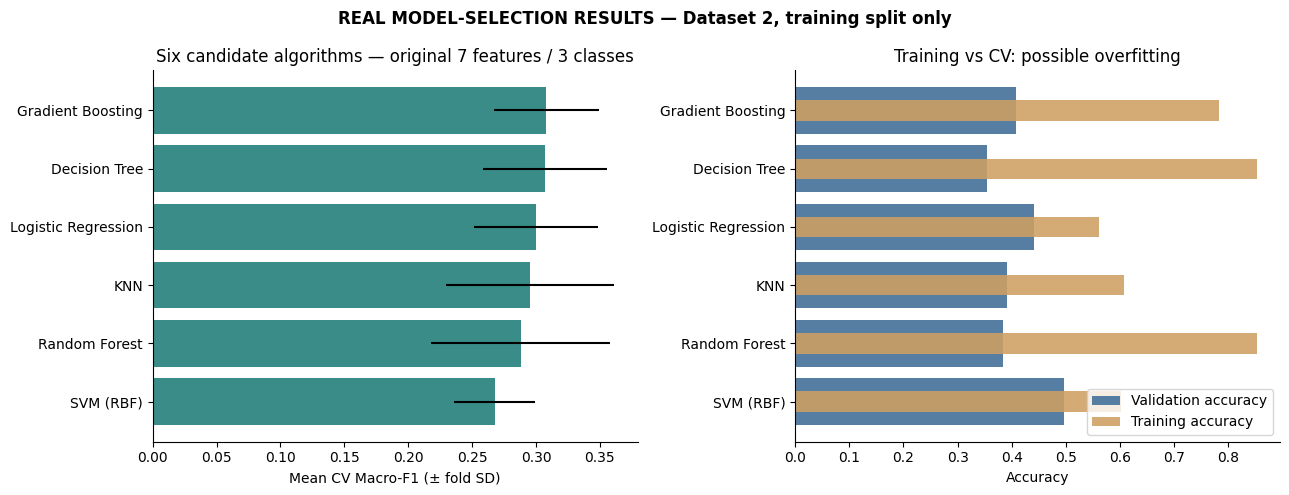

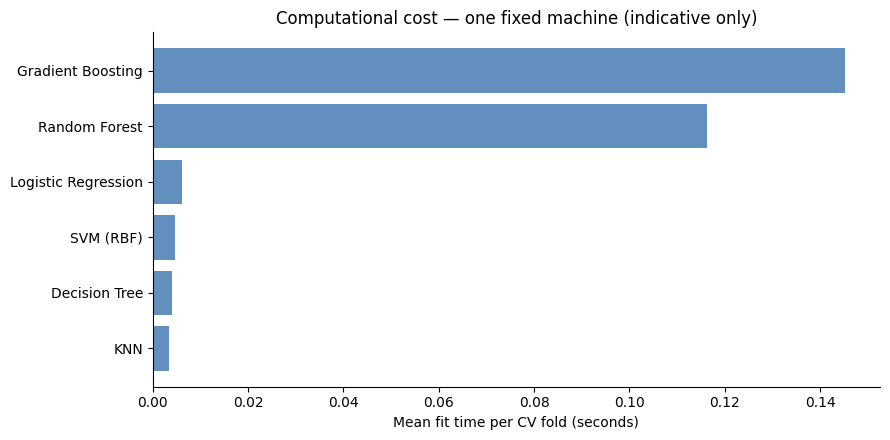

In [5]:
fig,axs=plt.subplots(1,2,figsize=(13,5))
order=results[results.group.ne('baseline')].sort_values('cv_macro_f1',ascending=False)
axs[0].barh(order['model'][::-1],order['cv_macro_f1'][::-1],xerr=order['cv_macro_f1_sd'][::-1],color='#398c88')
axs[0].set(xlabel='Mean CV Macro-F1 (± fold SD)',title='Six candidate algorithms — original 7 features / 3 classes')
axs[1].barh(order['model'][::-1],order['cv_accuracy'][::-1],color='#567ea3',label='Validation accuracy')
axs[1].barh(order['model'][::-1],order['cv_train_accuracy'][::-1],height=.35,color='#d0a062',alpha=.88,label='Training accuracy')
axs[1].set(xlabel='Accuracy',title='Training vs CV: possible overfitting')
axs[1].legend(loc='lower right')
fig.suptitle('REAL MODEL-SELECTION RESULTS — Dataset 2, training split only',fontweight='bold')
fig.tight_layout();fig.savefig(FIGURES/'model_selection_6_models.png',dpi=180,bbox_inches='tight');plt.show()
complexity=results[['model','group','mean_fit_time_seconds','mean_score_time_seconds','cv_train_accuracy','cv_accuracy']].copy()
complexity['train_validation_accuracy_gap']=complexity['cv_train_accuracy']-complexity['cv_accuracy']
complexity.to_csv(TABLES/'model_complexity.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.5))
ss=results[results.group.ne('baseline')].sort_values('mean_fit_time_seconds')
ax.barh(ss['model'],ss['mean_fit_time_seconds'],color='#628fbe')
ax.set(xlabel='Mean fit time per CV fold (seconds)',title='Computational cost — one fixed machine (indicative only)')
fig.tight_layout();fig.savefig(FIGURES/'training_time_comparison.png',dpi=180,bbox_inches='tight');plt.show()


### Interpretation note

On 300 self-reported observations, differences of only a few hundredths in Macro-F1 across 5 folds may be unstable. The selected simple and complex algorithms are **preliminary finalists**. High training accuracy with much lower validation accuracy suggests overfitting. Compare the Dummy baseline before making any usefulness claim.